# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [1]:
import pandas as pd
import numpy as np
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/hilase/Documents/octopus /home/hilase/Documents/octopus-slabs


# Going to the folder containing the database

In [28]:
DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"
%cd $DatabasePath

/home/hilase/Documents/octopus/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary


# Database loading and quick analysis

In [29]:
data=pd.read_csv("Database.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes


##JobID                           float64
RunDate                           float64
kgrid                             float64
realmesh                          float64
lambda1                           float64
tau1                              float64
Efield1                           float64
PolarizationAngle                 float64
CEP1                              float64
lambda2                           float64
tau2                              float64
Efield2                           float64
CEP2                              float64
delay                             float64
CrossPolar                        float64
TheoryLevel                       float64
InducedFields                     float64
ProbeFieldAmplitude (au)          float64
ProbeFieldDelay (s)               float64
Functional                        float64
FrozenHxc                         float64
MoveIon                           float64
NeMax                             float64
NeFinal                           

# Database filtering

In [30]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy afterpulse (eV),PoyntingEnergyFinal(eV),Eext_peak (V/m),N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,5905896.0,20180912.0,24.0,0.434637,1.060000e-06,2.000000e-14,1.000000e+08,0.000000,0.0,1.060000e-06,...,-0.000002,0.000044,5.688517e+10,2.310868e+21,9.408130e+34,1.155434e+35,3.0,2.0,3850.0,973.001435
1,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,8.000000e-07,...,0.006811,0.042002,-2.567970e+13,2.810199e+26,1.404822e+40,1.405099e+40,3.0,2.0,2262.5,937.147441
2,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.012292,0.047123,-3.133202e+14,4.712226e+26,1.570724e+40,1.570742e+40,3.0,2.0,3087.5,1350.561171
3,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.011922,0.046139,-1.059148e+14,4.433381e+26,1.477840e+40,1.477794e+40,3.0,2.0,3175.0,1350.561171
4,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.005908,0.034601,-4.980174e+13,2.513977e+26,8.378722e+39,8.379922e+39,3.0,2.0,3262.5,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2207,10309710.0,20210109.0,24.0,0.434637,2.656000e-06,3.000000e-14,3.000000e+09,0.125664,0.0,2.656000e-06,...,0.086828,1.118211,3.249914e+14,3.891359e+27,1.298236e+41,1.297120e+41,1.0,0.0,3500.0,2480.482380
2208,10309711.0,20210109.0,24.0,0.434637,2.656000e-06,3.000000e-14,9.000000e+09,0.125664,0.0,2.656000e-06,...,2.351216,108.217572,1.184838e+16,9.811313e+28,3.270510e+42,3.270438e+42,1.0,0.0,2875.0,2480.482380
2209,10309726.0,20210109.0,24.0,0.434637,2.656000e-06,3.000000e-14,3.000000e+09,0.753982,0.0,2.656000e-06,...,0.103852,0.758489,2.789699e+14,4.759755e+27,1.587801e+41,1.586585e+41,1.0,0.0,3500.0,2480.482380
2210,10309720.0,20210109.0,24.0,0.434637,2.656000e-06,3.000000e-14,3.000000e+09,0.502655,0.0,2.656000e-06,...,0.102804,1.015687,3.533547e+14,4.610573e+27,1.538177e+41,1.536858e+41,1.0,0.0,3500.0,2480.482380


In [31]:
data=data[data.kgrid==24]

In [32]:
data=data[data.Efield2==0]; #data=data[data.STH==1]; 

In [33]:
#data=data[data.CEP1==0]; 
data=data[data.InducedFields==0]
data=data[data.PolarizationAngle==0]

In [34]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "kgrid", "realmesh", "PolarizationAngle"], ascending=True)
datafull=data

In [35]:
datafull

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy afterpulse (eV),PoyntingEnergyFinal(eV),Eext_peak (V/m),N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
164,5109637.0,20180601.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+08,0.0,0.0,2.000000e-07,...,8.275290e-04,0.009362,-2.583857e+11,3.956736e+25,1.973568e+39,1.978368e+39,3.0,2.0,3812.5,854.407455
1473,8715191.0,20190625.0,24.0,0.434637,2.000000e-07,2.000000e-14,5.000000e+08,0.0,0.0,2.000000e-07,...,1.929118e-02,0.220193,-7.046549e+12,9.323632e+26,4.661432e+40,4.661816e+40,3.0,2.0,3125.0,854.407455
1528,8918119.0,20190708.0,24.0,0.434637,2.000000e-07,2.000000e-14,7.500000e+08,0.0,0.0,2.000000e-07,...,4.023641e-02,0.457986,-9.950841e+12,1.940491e+27,9.701183e+40,9.702455e+40,3.0,2.0,3125.0,854.407455
316,5027620.0,20180524.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+09,0.0,0.0,2.000000e-07,...,6.562037e-02,0.730740,5.249025e+12,3.098914e+27,1.549393e+41,1.549457e+41,3.0,2.0,2975.0,854.407455
1418,8918121.0,20190709.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.500000e+09,0.0,0.0,2.000000e-07,...,1.096135e-01,1.228928,-1.315329e+13,5.229122e+27,2.614998e+41,2.614561e+41,3.0,2.0,3125.0,854.407455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1408,10050046.0,20191101.0,24.0,0.434637,4.100000e-06,2.000000e-14,5.000000e+08,0.0,0.0,4.100000e-06,...,0.000000e+00,0.000133,4.772506e+13,0.000000e+00,2.465914e+35,0.000000e+00,3.0,2.0,3750.0,0.000000
1743,17608855.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,5.000000e+08,0.0,0.0,6.400000e-06,...,3.939855e-06,0.000122,9.126449e+13,4.818818e+21,7.342516e+34,8.031364e+34,3.0,2.0,7750.0,3363.042231
1740,17638129.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,7.500000e+08,0.0,0.0,6.400000e-06,...,-9.405643e-07,0.000332,7.494698e+13,7.783695e+23,1.286704e+37,1.297282e+37,3.0,2.0,7625.0,3363.042231
1716,17608858.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,1.000000e+09,0.0,0.0,6.400000e-06,...,4.586451e-04,0.003204,-5.717344e+12,1.598688e+25,2.664830e+38,2.664481e+38,3.0,2.0,7500.0,3363.042231


In [36]:
data=datafull
# data=data[data.lambda1==800e-9]
# data=data[data.lambda1<408e-9]
# data = data[data.lambda1>2600E-9]
# data = data[data.lambda1<2700e-9]

In [37]:
# data = data[data.Efield1==3E9]
data = data[data.CEP1!=0]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy afterpulse (eV),PoyntingEnergyFinal(eV),Eext_peak (V/m),N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
1622,9606980.0,20191022.0,24.0,0.434637,8.000000e-07,2.000000e-14,5.000000e+08,0.0,0.785398,8.000000e-07,...,0.001041,0.007516,6.344380e+12,4.467431e+25,2.224778e+39,2.233716e+39,3.0,2.0,3250.0,937.147441
1623,9606992.0,20191022.0,24.0,0.434637,8.000000e-07,2.000000e-14,5.000000e+08,0.0,0.523599,8.000000e-07,...,0.001209,0.007517,7.096578e+12,4.467650e+25,2.225445e+39,2.233825e+39,3.0,2.0,3125.0,937.147441
1638,9606978.0,20191022.0,24.0,0.434637,8.000000e-07,2.000000e-14,5.000000e+08,0.0,-0.785398,8.000000e-07,...,0.001279,0.007519,8.022521e+11,4.470771e+25,2.225760e+39,2.235386e+39,3.0,2.0,3250.0,937.147441
1651,9606993.0,20191022.0,24.0,0.434637,8.000000e-07,2.000000e-14,5.000000e+08,0.0,-1.047198,8.000000e-07,...,0.001139,0.007519,-1.015560e+12,4.470468e+25,2.226168e+39,2.235234e+39,3.0,2.0,3125.0,937.147441
1671,9606991.0,20191022.0,24.0,0.434637,8.000000e-07,2.000000e-14,5.000000e+08,0.0,1.047198,8.000000e-07,...,0.000921,0.007517,6.806466e+12,4.467647e+25,2.225471e+39,2.233824e+39,3.0,2.0,3125.0,937.147441
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1666,9607130.0,20191023.0,24.0,0.434637,2.200000e-06,2.000000e-14,5.000000e+08,0.0,-1.570796,2.200000e-06,...,-0.000001,0.000292,-9.440429e+13,1.171817e+23,5.423482e+36,5.859086e+36,3.0,2.0,3250.0,1130.207409
1669,9607138.0,20191023.0,24.0,0.434637,2.200000e-06,2.000000e-14,5.000000e+08,0.0,-1.047198,2.200000e-06,...,0.000009,0.000295,-4.406457e+13,1.239905e+23,5.751757e+36,6.199525e+36,3.0,2.0,3250.0,1130.207409
1701,9607134.0,20191023.0,24.0,0.434637,2.200000e-06,2.000000e-14,5.000000e+08,0.0,1.570796,2.200000e-06,...,-0.000001,0.000292,9.727434e+13,1.172760e+23,5.497656e+36,5.863801e+36,3.0,2.0,3125.0,1130.207409
1711,9607133.0,20191023.0,24.0,0.434637,2.200000e-06,2.000000e-14,5.000000e+08,0.0,0.785398,2.200000e-06,...,0.000004,0.000293,1.202407e+14,1.263356e+23,5.865374e+36,6.316780e+36,3.0,2.0,3250.0,1130.207409


In [38]:
data = data[data.STH==1]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy afterpulse (eV),PoyntingEnergyFinal(eV),Eext_peak (V/m),N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime


In [91]:
angle=data.PolarizationAngle;
Nexc=data.N_exc_afterpulse
Eabs=data."Energy (eV)"
angle; Nexc
from scipy.constants import pi
# plt.plot(angle*180./pi,Nexc)
plt.plot(angle*180./pi,Eabs)

SyntaxError: invalid syntax (<ipython-input-91-8b842dd714dc>, line 3)

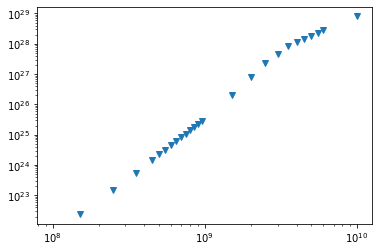

In [84]:
Efield=data.Efield1[data.lambda1==800e-9]
Nexc=data.N_exc_afterpulse[data.lambda1==800e-9]
angle=data.
plt.loglog(Efield, Nexc, "v")

In [15]:
data_missing=data[data.N_exc_afterpulse>2.5E28]

In [16]:
data_missing=data_missing[data_missing.N_exc_afterpulse < 1E29]

In [17]:
data_missing

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy afterpulse (eV),PoyntingEnergyFinal(eV),Eext_peak (V/m),N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2051,5691121.0,20180805.0,24.0,0.434637,8.000000e-07,2.000000e-14,6.000000e+09,0.0,0.0,8.000000e-07,...,0.0,12.719791,1.778758e+15,2.876276e+28,1.438038e+42,1.438138e+42,3.0,2.0,1512.5,1047.467469
2262,5691121.0,20180805.0,24.0,0.434637,8.000000e-07,2.000000e-14,6.000000e+09,0.0,0.0,8.000000e-07,...,0.0,12.573560,1.778758e+15,2.876276e+28,1.438038e+42,1.438138e+42,3.0,2.0,1512.5,937.147441
2026,5630603.0,20180928.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.000000e+10,0.0,0.0,8.000000e-07,...,0.0,75.841051,-8.902123e+15,7.995364e+28,3.997316e+42,3.997682e+42,3.0,2.0,3075.0,1047.467469
2237,5630603.0,20180928.0,24.0,0.434637,8.000000e-07,2.000000e-14,1.000000e+10,0.0,0.0,8.000000e-07,...,0.0,74.928134,-8.902124e+15,7.995364e+28,3.997316e+42,3.997682e+42,3.0,2.0,3075.0,937.147441


In [19]:
temp=datafull[datafull.tau1>29e-15]
temp[temp.tau1<31e-15]

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy afterpulse (eV),PoyntingEnergyFinal(eV),Eext_peak (V/m),N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
1543,8496863.0,20190611.0,24.0,0.434637,2.000000e-07,3.000000e-14,2.000000e+09,0.0,0.0,2.000000e-07,...,0.126278,1.322913,9.267287e+13,5.962447e+27,1.988901e+41,1.987482e+41,3.0,2.0,3000.0,1267.821185
1178,8496864.0,20190611.0,24.0,0.434637,3.000000e-07,3.000000e-14,2.000000e+09,0.0,0.0,3.000000e-07,...,0.321762,2.105754,4.965578e+14,1.132263e+28,3.772087e+41,3.774210e+41,3.0,2.0,3000.0,1281.611183
1575,8496865.0,20190611.0,24.0,0.434637,3.430000e-07,3.000000e-14,2.000000e+09,0.0,0.0,3.430000e-07,...,0.282118,1.806203,-2.864666e+14,1.007333e+28,3.356664e+41,3.357778e+41,3.0,2.0,3000.0,1287.540882
1571,8496867.0,20190612.0,24.0,0.434637,4.000000e-07,3.000000e-14,2.000000e+09,0.0,0.0,4.000000e-07,...,0.199984,1.298226,9.486836e+13,7.123391e+27,2.374853e+41,2.374464e+41,3.0,2.0,3000.0,1295.401180
1413,8496870.0,20190612.0,24.0,0.434637,5.000000e-07,3.000000e-14,2.000000e+09,0.0,0.0,5.000000e-07,...,0.132703,1.155478,-4.074803e+13,5.560687e+27,1.852686e+41,1.853562e+41,3.0,2.0,2875.0,1309.191178
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1511,8094101.0,20190517.0,24.0,0.434637,3.200000e-06,3.000000e-14,5.000000e+10,0.0,0.0,3.200000e-06,...,5.257341,5064.163855,3.246072e+16,1.995907e+29,6.653011e+42,6.653023e+42,3.0,2.0,3875.0,1681.521115
1201,8094106.0,20190517.0,24.0,0.434637,3.200000e-06,3.000000e-14,6.000000e+10,0.0,0.0,3.200000e-06,...,5.257332,5065.885271,2.850367e+17,1.995967e+29,6.653214e+42,6.653224e+42,3.0,2.0,3875.0,1681.521115
1224,8094112.0,20190518.0,24.0,0.434637,3.200000e-06,3.000000e-14,7.000000e+10,0.0,0.0,3.200000e-06,...,5.257331,5067.862349,3.330183e+17,1.995965e+29,6.653204e+42,6.653217e+42,3.0,2.0,3875.0,1681.521115
1501,7962747.0,20190518.0,24.0,0.434637,3.200000e-06,3.000000e-14,8.000000e+10,0.0,0.0,3.200000e-06,...,5.257340,5071.333200,1.846463e+17,1.995962e+29,6.653201e+42,6.653208e+42,3.0,2.0,3875.0,1681.521115
